   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 14.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 11.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


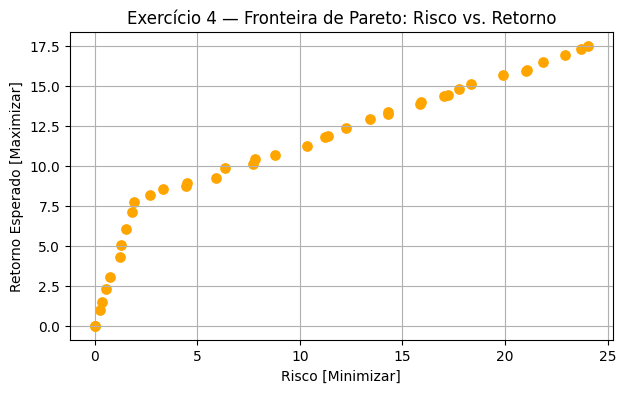

RF=0.0% | Ações=0.0% | risco=0.00 | retorno=0.00
RF=0.0% | Ações=0.0% | risco=0.00 | retorno=0.00
RF=12.1% | Ações=0.0% | risco=0.25 | retorno=0.97
RF=18.7% | Ações=0.0% | risco=0.37 | retorno=1.49
RF=28.4% | Ações=0.0% | risco=0.57 | retorno=2.27


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize


class PortfolioProblem(ElementwiseProblem):
    def __init__(self):
        # x1: % Renda Fixa (0 a 100), x2: % Ações (0 a 100)
        # 1 restrição de desigualdade: o total investido não pode passar de 100%
        super().__init__(n_var=2, n_obj=2, n_ieq_constr=1,
                         xl=np.array([0.0, 0.0]), xu=np.array([100.0, 100.0]))

    def _evaluate(self, x, out, *args, **kwargs):
        rf, acoes = x[0], x[1]

        # TODO 1: retorno negativo (para maximizar o retorno)
        f1_retorno_negativo = -(rf * 0.08 + acoes * 0.18)

        # TODO 2: risco (minimizar)
        f2_risco = rf * 0.02 + acoes * 0.25

        # Restrição de investimento: rf + acoes <= 100  ->  g(x) <= 0
        g1 = rf + acoes - 100.0

        out["F"] = [f1_retorno_negativo, f2_risco]
        out["G"] = [g1]


# TODO 3: executar o NSGA-II
res4 = minimize(PortfolioProblem(), NSGA2(pop_size=40),
                termination=('n_gen', 50), seed=1)

# Ordena por risco para o gráfico ficar limpo
idx = np.argsort(res4.F[:, 1])
risco = res4.F[idx, 1]
retorno_real = -res4.F[idx, 0]          # reverte o sinal

plt.figure(figsize=(7, 4))
plt.scatter(risco, retorno_real, color='orange', s=45)
plt.title("Exercício 4 — Fronteira de Pareto: Risco vs. Retorno")
plt.xlabel("Risco [Minimizar]")
plt.ylabel("Retorno Esperado [Maximizar]")
plt.grid(True)
plt.show()

# Alocações correspondentes (opcional, bom para o relatório)
for (rf, ac), r, ret in list(zip(res4.X[idx], risco, retorno_real))[:5]:
    print(f"RF={rf:.1f}% | Ações={ac:.1f}% | risco={r:.2f} | retorno={ret:.2f}")